#  11 (Lanjutan) — Image Retrieval: Teks, Isi Visual, dan CLIP

**Tujuan praktikum**
1. Mahasiswa memahami tiga pendekatan temu kembali gambar: berbasis teks (caption), berbasis isi visual (CBIR), dan multimodal (CLIP).
2. Mahasiswa mampu melakukan pencarian **teks → gambar** dan **gambar → gambar** (*query by example*).
3. Mahasiswa memahami pembelajaran kontrastif teks–gambar ala CLIP dengan melatih versi mininya.
4. Mahasiswa mampu menggabungkan skor teks dan gambar (*hybrid*) untuk dokumen yang berisi teks dan gambar, lalu mengevaluasinya dengan MAP dan nDCG.

**Dua koleksi gambar** tersimpan di folder `../data/images/`:
- **Bagian A** (`foto/`, `foto.csv`, `foto_queries.csv`, `foto_qrels.csv`): 18 foto beserta caption berbahasa Indonesia, 8 query teks, dan penilaian relevansinya. Foto berasal dari contoh bawaan pustaka `scikit-image`.
- **Bagian B** (`angka/`, `angka.csv`): 1.797 gambar angka tulisan tangan 8×8 piksel dari `scikit-learn`, beserta label angka dan pembagian data latih/uji. Label angka dipakai sebagai penilaian relevansi.

Struktur ini sama dengan koleksi teks (`korpus.csv`, `queries.csv`, `qrels.csv`), sehingga Anda dapat mengganti gambarnya dengan koleksi sendiri cukup dengan menyalin file dan memperbarui CSV.

**Model pretrained.** Bagian A3 mencoba mengunduh CLIP pretrained dari Hugging Face (`clip-ViT-B-32` untuk gambar dan `clip-ViT-B-32-multilingual-v1` untuk teks berbahasa Indonesia). Jika tidak ada koneksi internet, bagian itu dilewati dan Bagian B melatih **CLIP mini** secara lokal.

In [1]:
# Jalankan sekali jika pustaka belum terpasang:
# !pip install scikit-image scikit-learn torch sentence-transformers pillow pandas numpy matplotlib Sastrawi
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from PIL import Image
from stki_utils import preprocess, BM25Model, average_precision, ndcg_at_k

torch.manual_seed(0); random.seed(0); np.random.seed(0)
DIR_GAMBAR = Path("../data/images")

# Bagian A — Koleksi foto

## Langkah A0 — Memuat foto dan caption
Setiap foto disimpan bersama caption, seperti gambar di halaman web yang punya *alt-text* atau keterangan.

  image_id                    file  \
0      F01  foto/F01_astronaut.jpg   
1      F02      foto/F02_brick.jpg   
2      F03     foto/F03_camera.jpg   
3      F04    foto/F04_chelsea.jpg   
4      F05      foto/F05_clock.jpg   

                                             caption  
0  foto astronot perempuan berpakaian antariksa d...  
1                       tekstur dinding bata abu-abu  
2  fotografer pria memegang kamera di taman, foto...  
3            kucing belang oranye menatap ke samping  
4                                 jam dinding analog  


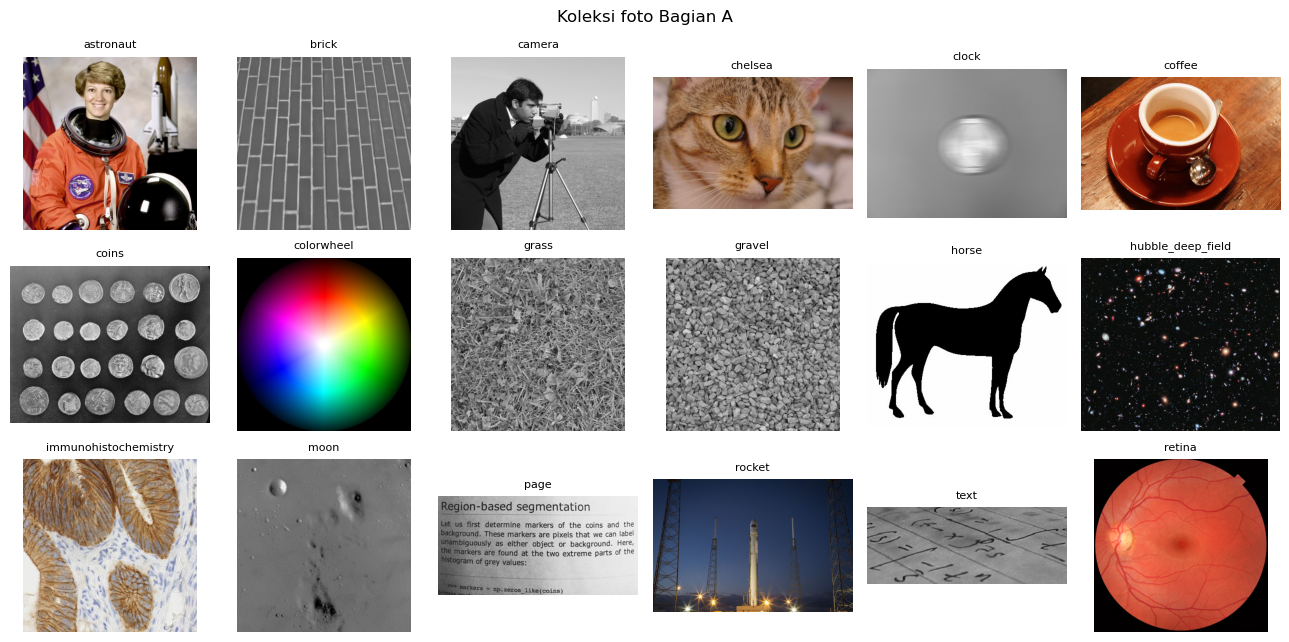

In [2]:
meta_foto = pd.read_csv(DIR_GAMBAR / "foto.csv")
# nama pendek dari nama file, misalnya foto/F06_coffee.jpg -> coffee
meta_foto["nama"] = meta_foto["file"].str.extract(r"F\d+_(.+)\.jpg")[0]
foto = {r.nama: np.asarray(Image.open(DIR_GAMBAR / r.file).convert("RGB")) for r in meta_foto.itertuples()}
CAPTION = dict(zip(meta_foto.nama, meta_foto.caption))
id_ke_nama = dict(zip(meta_foto.image_id, meta_foto.nama))
nama = list(foto)

# query teks dan penilaian relevansi untuk koleksi foto
query_foto = dict(pd.read_csv(DIR_GAMBAR / "foto_queries.csv").values)
qrels_foto = {}
for q, iid, r in pd.read_csv(DIR_GAMBAR / "foto_qrels.csv").values:
    qrels_foto.setdefault(q, set()).add(id_ke_nama[iid])

print(meta_foto[["image_id", "file", "caption"]].head())
fig, axes = plt.subplots(3, 6, figsize=(13, 6.5))
for ax, n in zip(axes.ravel(), nama):
    ax.imshow(foto[n]); ax.set_title(n, fontsize=8); ax.axis("off")
plt.suptitle("Koleksi foto Bagian A"); plt.tight_layout(); plt.show()

## Langkah A1 — Pendekatan 1: retrieval berbasis teks (caption)
Gambar diwakili oleh teksnya, lalu diindeks dengan BM25 seperti dokumen biasa. Pada sistem nyata teks ini bisa berasal dari caption, alt-text, nama file, paragraf di sekitarnya, **OCR** (untuk gambar berisi tulisan), atau **image captioning** otomatis.

'kucing'        -> [('chelsea', 2.500178005456367)]
'tekstur batu'  -> [('gravel', 4.58649893720191), ('grass', 2.297826899740567), ('brick', 1.6658269714587812)]
'luar angkasa'  -> [('hubble_deep_field', 4.580419425237325)]


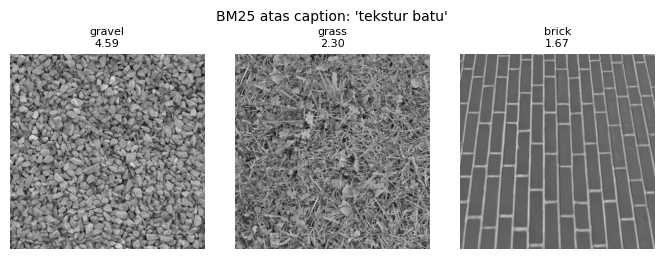

In [3]:
bm25_caption = BM25Model({n: preprocess(c) for n, c in CAPTION.items()})

def tampilkan(hasil, judul):
    fig, axes = plt.subplots(1, len(hasil), figsize=(2.3 * len(hasil), 2.6))
    for ax, (n, s) in zip(np.atleast_1d(axes), hasil):
        ax.imshow(foto[n]); ax.set_title(f"{n}\n{s:.2f}", fontsize=8); ax.axis("off")
    fig.suptitle(judul, fontsize=10); plt.tight_layout(); plt.show()

for q in ["kucing", "tekstur batu", "luar angkasa"]:
    hasil = bm25_caption.search(preprocess(q), k=3)
    print(f"{q!r:15s} -> {hasil}")
tampilkan(bm25_caption.search(preprocess("tekstur batu"), k=3), "BM25 atas caption: 'tekstur batu'")

In [4]:
# evaluasi teks -> gambar pada 8 query foto
def eval_foto(fungsi_cari):
    baris = []
    for q, teks_q in query_foto.items():
        urut = fungsi_cari(teks_q)
        baris.append({"query": teks_q, "relevan": ", ".join(sorted(qrels_foto[q])),
                      "AP": average_precision(urut, qrels_foto[q])})
    df = pd.DataFrame(baris)
    print(f"MAP = {df.AP.mean():.4f}")
    return df.round(4)

eval_foto(lambda q: [n for n, _ in bm25_caption.search(preprocess(q), k=len(nama))])

MAP = 0.6354


,query,relevan,AP
0,kucing,chelsea,1.0000
1,luar angkasa,"astronaut, hubble_deep_field, moon, rocket",0.2500
2,tekstur batu,"brick, gravel",0.8333
3,minuman hangat,coffee,0.0000
4,citra medis,"immunohistochemistry, retina",1.0000
5,dokumen bertulisan,"page, text",1.0000
6,hewan,"chelsea, horse",0.0000
7,uang logam,coins,1.0000


Perhatikan query `luar angkasa`: foto astronot, bulan, dan roket tidak ditemukan karena caption-nya tidak memuat kata *luar angkasa* (foto astronot memakai kata *antariksa*). Query `minuman hangat` dan `hewan` bahkan mendapat AP 0, karena caption memakai kata *kopi*, *kucing*, dan *kuda*. Ini masalah *vocabulary mismatch* yang sama seperti pada teks (Bab 8–9). Selain itu, gambar tanpa caption sama sekali tidak dapat ditemukan.

## Langkah A2 — Pendekatan 2: Content-Based Image Retrieval (CBIR)
Isi visual gambar diubah menjadi **vektor fitur**. Fitur klasik yang paling sederhana adalah **histogram warna**: sebaran nilai merah, hijau, dan biru. Query berupa gambar (*query by example*). Untuk mengujinya, setiap foto dimodifikasi (dipotong, dicerminkan, dan digelapkan), lalu dijadikan query; sistem yang baik harus menempatkan foto aslinya di peringkat 1.

In [5]:
def histogram_warna(img, bins=16):
    h = [np.histogram(img[..., c], bins=bins, range=(0, 256))[0] for c in range(3)]
    v = np.concatenate(h).astype(float)
    return v / np.linalg.norm(v)

def ubah(img):
    h, w = img.shape[:2]
    potong = img[h // 10: h - h // 10, w // 10: w - w // 10]      # potong 10% tiap sisi
    return (potong[:, ::-1] * 0.85).astype(np.uint8)                # cermin + lebih gelap

fitur_hist = np.array([histogram_warna(foto[n]) for n in nama])
baris = []
for i, n in enumerate(nama):
    skor = fitur_hist @ histogram_warna(ubah(foto[n]))
    urut = [nama[j] for j in np.argsort(-skor)]
    baris.append({"query (versi diubah)": n, "peringkat foto asli": urut.index(n) + 1, "hasil teratas": urut[0]})
cbir = pd.DataFrame(baris)
print(f"MRR histogram warna: {np.mean(1 / cbir['peringkat foto asli']):.3f}")
cbir

MRR histogram warna: 0.617


,query (versi diubah),peringkat foto asli,hasil teratas
0,astronaut,1,astronaut
1,brick,7,grass
2,camera,1,camera
3,chelsea,1,chelsea
4,clock,6,moon
5,coffee,1,coffee
6,coins,1,coins
7,colorwheel,2,astronaut
8,grass,1,grass
9,gravel,2,grass


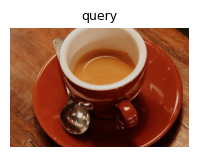

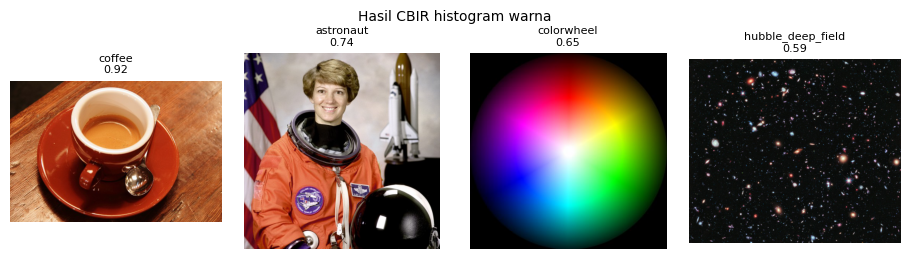

In [6]:
q = ubah(foto["coffee"])
hasil = [(nama[j], float(fitur_hist[j] @ histogram_warna(q))) for j in np.argsort(-(fitur_hist @ histogram_warna(q)))[:4]]
fig, ax = plt.subplots(figsize=(2.3, 2.3)); ax.imshow(q); ax.set_title("query", fontsize=9); ax.axis("off"); plt.show()
tampilkan(hasil, "Hasil CBIR histogram warna")

Histogram warna tahan terhadap pencerminan dan pemotongan, tetapi tidak memahami **isi** gambar: dua foto hitam putih yang sama sekali berbeda bisa memiliki histogram mirip. Fitur modern memakai embedding dari jaringan saraf (CNN atau Vision Transformer) yang menangkap bentuk dan objek.

## Langkah A3 — Pendekatan 3: CLIP pretrained (memerlukan internet)
**CLIP** melatih *encoder gambar* dan *encoder teks* secara bersamaan agar pasangan gambar–teks yang cocok memiliki vektor berdekatan dalam **satu ruang vektor**. Dengan begitu, query teks dapat langsung dibandingkan dengan gambar, tanpa caption.

In [7]:
try:
    from sentence_transformers import SentenceTransformer
    clip_gambar = SentenceTransformer("clip-ViT-B-32")
    clip_teks = SentenceTransformer("sentence-transformers/clip-ViT-B-32-multilingual-v1")
    PAKAI_CLIP = True
except Exception as e:
    PAKAI_CLIP = False
    print("CLIP pretrained tidak dapat diunduh:", type(e).__name__)
    print("-> Langkah A3 dilewati; mekanisme CLIP dipelajari lewat CLIP mini di Bagian B")

if PAKAI_CLIP:
    emb_foto = clip_gambar.encode([Image.fromarray(foto[n]) for n in nama], normalize_embeddings=True)
    def cari_clip(q):
        skor = emb_foto @ clip_teks.encode([q], normalize_embeddings=True)[0]
        return [nama[j] for j in np.argsort(-skor)]
    display(eval_foto(cari_clip))   # bandingkan dengan MAP BM25 atas caption di Langkah A1
    peringkat = []
    for i, n in enumerate(nama):
        qv = clip_gambar.encode([Image.fromarray(ubah(foto[n]))], normalize_embeddings=True)[0]
        peringkat.append(list(np.argsort(-(emb_foto @ qv))).index(i) + 1)
    print(f"MRR gambar -> gambar dengan CLIP: {np.mean(1 / np.array(peringkat)):.3f}")

CLIP pretrained tidak dapat diunduh: ModuleNotFoundError
-> Langkah A3 dilewati; mekanisme CLIP dipelajari lewat CLIP mini di Bagian B


# Bagian B — Koleksi angka tulisan tangan

## Langkah B0 — Data, caption, dan penilaian relevansi
Gambar dibaca dari `../data/images/angka/` dan pembagian data latih (70%) serta koleksi uji (30%) dibaca dari kolom `split` di `angka.csv`. Saat pelatihan, setiap gambar diberi caption dari beberapa templat kalimat. Gambar di koleksi uji dianggap **relevan** terhadap query "angka tujuh" jika labelnya 7.

  image_id             file  label label_kata  split
0    A0000  angka/A0000.png      0        nol  latih
1    A0001  angka/A0001.png      1       satu  latih
2    A0002  angka/A0002.png      2        dua  latih
Data latih: (1257, 64) | koleksi uji: (540, 64)


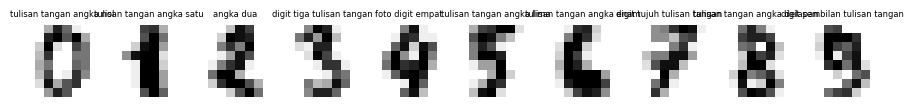

In [8]:
meta_angka = pd.read_csv(DIR_GAMBAR / "angka.csv")
print(meta_angka.head(3))

def muat(df):
    X = np.stack([np.asarray(Image.open(DIR_GAMBAR / f), dtype=float).ravel() / 255.0 for f in df.file])
    return X, df.label.to_numpy(), df.image_id.tolist()

X_latih, y_latih, _ = muat(meta_angka[meta_angka.split == "latih"])
X_uji, y_uji, ids = muat(meta_angka[meta_angka.split == "uji"])

KATA = ["nol", "satu", "dua", "tiga", "empat", "lima", "enam", "tujuh", "delapan", "sembilan"]
TEMPLAT = ["angka {}", "gambar angka {}", "digit {} tulisan tangan", "tulisan tangan angka {}", "foto digit {}"]
query_teks = {k: f"angka {KATA[k]}" for k in range(10)}
relevan = {k: {ids[i]: 1 for i in range(len(ids)) if y_uji[i] == k} for k in range(10)}
print("Data latih:", X_latih.shape, "| koleksi uji:", X_uji.shape)

fig, axes = plt.subplots(1, 10, figsize=(11, 1.6))
for k, ax in enumerate(axes):
    ax.imshow(X_latih[y_latih == k][0].reshape(8, 8), cmap="gray_r"); ax.set_title(random.choice(TEMPLAT).format(KATA[k]), fontsize=6); ax.axis("off")
plt.show()

## Langkah B1 — CBIR dengan fitur piksel mentah
Baseline gambar → gambar: setiap gambar direpresentasikan sebagai vektor 64 nilai piksel. Setiap gambar ke-5 di koleksi uji dijadikan query; gambar lain dengan angka yang sama dianggap relevan.

In [9]:
def eval_gambar_ke_gambar(fitur):
    Fn = fitur / np.linalg.norm(fitur, axis=1, keepdims=True)
    ap, nd = [], []
    for i in range(0, len(ids), 5):
        skor = Fn @ Fn[i]; skor[i] = -np.inf
        urut = [ids[j] for j in np.argsort(-skor) if j != i]
        rel = {ids[j]: 1 for j in range(len(ids)) if y_uji[j] == y_uji[i] and j != i}
        ap.append(average_precision(urut, set(rel))); nd.append(ndcg_at_k(urut, rel, 10))
    return np.mean(ap), np.mean(nd)

hasil_b = {"Gambar -> gambar, piksel mentah": eval_gambar_ke_gambar(X_uji)}
print("MAP, nDCG@10:", np.round(hasil_b["Gambar -> gambar, piksel mentah"], 4))

MAP, nDCG@10: [0.6597 0.9156]


## Langkah B2 — Melatih CLIP mini
Arsitektur CLIP mini:
- **Encoder gambar**: MLP 64 → 128 → 32.
- **Encoder teks**: rata-rata embedding kata (`EmbeddingBag`) → 32.
- Kedua keluaran dinormalisasi sehingga kemiripan dihitung dengan cosine.

**Fungsi loss kontrastif (InfoNCE simetris).** Dalam satu batch berisi $N$ pasangan (gambar, caption), matriks kemiripan $S_{ij} = \cos(\text{img}_i, \text{txt}_j) \cdot e^{t}$ dihitung. Loss mendorong nilai diagonal (pasangan yang cocok) lebih besar daripada nilai lain pada baris dan kolom yang sama. Karena satu batch bisa berisi beberapa gambar dengan angka sama, semua pasangan berlabel sama diperlakukan sebagai positif (CLIP asli hanya menganggap diagonal sebagai positif).

Loss awal 4.519, akhir 1.928


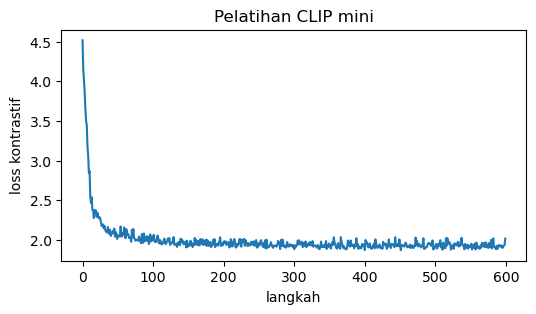

In [10]:
kosakata = sorted({w for t in TEMPLAT for w in t.format("").split()} | set(KATA))
w2i = {w: i for i, w in enumerate(kosakata)}

def token(s):
    return torch.tensor([w2i[w] for w in s.lower().split() if w in w2i], dtype=torch.long)

class EncoderGambar(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 32))
    def forward(self, x):
        return F.normalize(self.net(x), dim=-1)

class EncoderTeks(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.EmbeddingBag(len(kosakata), 64, mode="mean")
        self.proj = nn.Linear(64, 32)
    def forward(self, daftar_token):
        flat = torch.cat(daftar_token)
        offset = torch.tensor([0] + [len(t) for t in daftar_token[:-1]]).cumsum(0)
        return F.normalize(self.proj(self.emb(flat, offset)), dim=-1)

enc_img, enc_txt = EncoderGambar(), EncoderTeks()
log_suhu = nn.Parameter(torch.tensor(2.0))
opt = torch.optim.Adam(list(enc_img.parameters()) + list(enc_txt.parameters()) + [log_suhu], lr=3e-3)
Xt = torch.tensor(X_latih, dtype=torch.float32)
riwayat = []
for step in range(600):
    idx = np.random.choice(len(X_latih), 64, replace=False)
    caption = [random.choice(TEMPLAT).format(KATA[y_latih[i]]) for i in idx]
    logits = enc_img(Xt[idx]) @ enc_txt([token(c) for c in caption]).T * log_suhu.exp()
    sama = torch.tensor(y_latih[idx][:, None] == y_latih[idx][None, :], dtype=torch.float32)
    target = sama / sama.sum(1, keepdim=True)
    loss = (F.cross_entropy(logits, target) + F.cross_entropy(logits.T, target)) / 2
    loss.backward(); opt.step(); opt.zero_grad()
    riwayat.append(loss.item())
print(f"Loss awal {riwayat[0]:.3f}, akhir {np.mean(riwayat[-50:]):.3f}")
plt.figure(figsize=(6, 3)); plt.plot(riwayat); plt.xlabel("langkah"); plt.ylabel("loss kontrastif")
plt.title("Pelatihan CLIP mini"); plt.show()

## Langkah B3 — Teks → gambar
Query teks dan semua gambar di koleksi uji dikodekan ke ruang vektor yang sama, lalu diurutkan dengan cosine similarity.

MAP, nDCG@10: [0.9952 1.    ]


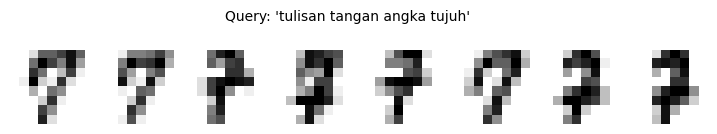

In [12]:
enc_img.eval(); enc_txt.eval()
with torch.no_grad():
    emb_uji = enc_img(torch.tensor(X_uji, dtype=torch.float32)).numpy()

def cari_teks(q, k=None):
    with torch.no_grad():
        qv = enc_txt([token(q)]).numpy()[0]
    skor = emb_uji @ qv
    urut = np.argsort(-skor)
    return [ids[j] for j in (urut if k is None else urut[:k])]

ap = [average_precision(cari_teks(q), set(relevan[k])) for k, q in query_teks.items()]
nd = [ndcg_at_k(cari_teks(q), relevan[k], 10) for k, q in query_teks.items()]
hasil_b["Teks -> gambar, CLIP mini"] = (np.mean(ap), np.mean(nd))
print("MAP, nDCG@10:", np.round(hasil_b["Teks -> gambar, CLIP mini"], 4))

fig, axes = plt.subplots(1, 8, figsize=(9, 1.6))
for ax, d in zip(axes, cari_teks("tulisan tangan angka tujuh", k=8)):
    ax.imshow(X_uji[ids.index(d)].reshape(8, 8), cmap="gray_r"); ax.axis("off")
fig.suptitle("Query: 'tulisan tangan angka tujuh'", fontsize=10); plt.show()

## Langkah B4 — Gambar → gambar dengan embedding CLIP mini
Encoder gambar yang sama dipakai untuk *query by example*. Bandingkan dengan fitur piksel mentah dari Langkah B1.

In [13]:
hasil_b["Gambar -> gambar, CLIP mini"] = eval_gambar_ke_gambar(emb_uji)
print("MAP, nDCG@10:", np.round(hasil_b["Gambar -> gambar, CLIP mini"], 4))

MAP, nDCG@10: [0.9715 0.9797]


## Langkah B5 — Keterbatasan: kosakata tertutup
CLIP mini hanya mengenal kata yang ada di caption latih. Kata di luar kosakata diabaikan, sehingga query seperti "angka 7" (memakai simbol) atau "bilangan prima" tidak dipahami. CLIP pretrained dilatih pada ratusan juta pasangan gambar–teks dari web sehingga kosakatanya terbuka.

In [14]:
for q in ["angka tujuh", "angka 7", "bilangan prima"]:
    dikenal = [w for w in q.split() if w in w2i]
    print(f"{q!r:18s} kata dikenal: {dikenal}")

'angka tujuh'      kata dikenal: ['angka', 'tujuh']
'angka 7'          kata dikenal: ['angka']
'bilangan prima'   kata dikenal: []


## Langkah B6 — Dokumen berisi teks dan gambar: retrieval hybrid
Bayangkan koleksi uji adalah dokumen yang masing-masing berisi satu gambar, tetapi hanya 40% yang memiliki caption (sisanya tanpa keterangan, seperti banyak gambar di web). Kita bandingkan tiga cara:
- **Teks saja**: BM25 atas caption.
- **Gambar saja**: CLIP mini teks → gambar.
- **Hybrid**: $\lambda \cdot \text{BM25}_{\text{norm}} + (1-\lambda) \cdot \cos_{\text{CLIP}}$, sama seperti hybrid di Bab 9.

In [15]:
rng = np.random.RandomState(1)
punya_caption = rng.rand(len(ids)) < 0.4
dok_teks = {ids[i]: (preprocess(f"foto digit {KATA[y_uji[i]]}") if punya_caption[i] else []) for i in range(len(ids))}
bm25_dok = BM25Model({d: t for d, t in dok_teks.items() if t})
print(f"Dokumen dengan caption: {punya_caption.sum()} dari {len(ids)}")

def hybrid(q, lam):
    b = dict(bm25_dok.search(preprocess(q), k=len(ids)))
    mx = max(b.values()) if b else 1.0
    with torch.no_grad():
        qv = enc_txt([token(q)]).numpy()[0]
    skor = {d: lam * b.get(d, 0) / mx + (1 - lam) * float(emb_uji[i] @ qv) for i, d in enumerate(ids)}
    return sorted(skor, key=lambda d: (-skor[d], d))

tabel = {}
for lam, label in [(1.0, "Teks saja (BM25 caption)"), (0.0, "Gambar saja (CLIP mini)"), (0.5, "Hybrid (lambda=0,5)")]:
    ap = [average_precision(hybrid(q, lam), set(relevan[k])) for k, q in query_teks.items()]
    nd = [ndcg_at_k(hybrid(q, lam), relevan[k], 10) for k, q in query_teks.items()]
    tabel[label] = {"MAP": np.mean(ap), "nDCG@10": np.mean(nd)}
pd.DataFrame(tabel).T.round(4)

Dokumen dengan caption: 208 dari 540


,MAP,nDCG@10
Teks saja (BM25 caption),0.4587,0.9
Gambar saja (CLIP mini),0.9952,1.0
"Hybrid (lambda=0,5)",0.9973,1.0


Dengan hanya caption, sekitar 60% gambar relevan tidak pernah ditemukan sehingga MAP rendah. Representasi visual membuat semua gambar dapat ditemukan, dan hybrid menggabungkan kepastian kecocokan kata dengan kemampuan "melihat" isi gambar.

## Langkah B7 — Ringkasan Bagian B

In [16]:
pd.DataFrame(hasil_b, index=["MAP", "nDCG@10"]).T.round(4)

,MAP,nDCG@10
"Gambar -> gambar, piksel mentah",0.6597,0.9156
"Teks -> gambar, CLIP mini",0.9952,1.0000
"Gambar -> gambar, CLIP mini",0.9715,0.9797


**Catatan hasil.** Nilai CLIP mini sangat tinggi karena tugasnya sederhana: 10 kelas angka dan query yang kosakatanya sama dengan caption latih. Pada foto dunia nyata dengan query bebas, CLIP mini seperti ini tidak akan bekerja; dibutuhkan CLIP pretrained (Langkah A3).

## Tugas 11
1. Jalankan Langkah A3 dengan koneksi internet. Bandingkan MAP teks → gambar CLIP dengan BM25 atas caption (Langkah A1), terutama untuk query "luar angkasa", dan bandingkan MRR gambar → gambar CLIP dengan histogram warna.
2. Tambahkan fitur tekstur (misalnya `skimage.feature.hog` atau *local binary pattern*) pada CBIR Langkah A2. Apakah MRR membaik?
3. Ubah proporsi dokumen yang memiliki caption di Langkah B6 (10%, 40%, 80%) dan gambarkan grafik MAP untuk teks saja, gambar saja, dan hybrid.
4. Latih CLIP mini hanya dengan pasangan diagonal sebagai positif (seperti CLIP asli). Bagaimana pengaruhnya terhadap MAP?
5. Dengan koneksi internet, pakai model *image captioning* (misalnya BLIP) atau OCR (misalnya `pytesseract`) untuk membuat teks otomatis dari foto Bagian A, lalu indeks teks tersebut dengan BM25. Bandingkan dengan caption buatan manusia.
6. Diskusikan: bagaimana menyimpan dan mencari jutaan embedding gambar secara efisien (FAISS, *approximate nearest neighbor*)?
7. Ganti koleksi foto dengan minimal 50 foto Anda sendiri (misalnya foto produk atau kampus). Simpan di `data/images/foto/`, perbarui `foto.csv`, buat minimal 5 query beserta `foto_qrels.csv`, lalu jalankan ulang Bagian A.

In [16]:
# Tulis jawaban Anda di sini